# Do related keys sit close together?

*Question 3 of the latent-space analysis: does a bit of music theory emerge?*

Western music uses 12 keys, and some of them sound much more closely related than others. A
piece in C major uses the notes C, D, E, F, G, A and B. The key of G major uses six of those
same seven notes, so moving between C and G sounds smooth; the key of F♯ major shares only two
of them, so it sounds far away. Musicians arrange the keys around the **circle of fifths**
(C, G, D, A, E, B, F♯, D♭, A♭, E♭, B♭, F, and back to C), where neighbours are closely related
and opposite keys are distant.

The model was never told about keys. But if it learned which notes tend to go together, it may
have placed related keys close to each other in its code anyway. To find out, we play the same
bars in all 12 keys, encode each version, and measure how far apart the versions end up.

We compare the **compact** (β = 0.1) and **detailed** (β = 0.01) models with the **untrained**
control, and with a simple reference: the distance between the keys measured only by which note
names the bars use. The bars are 600 bars of the validation pieces, first transposed to C, then
played in each key within half an octave of C, so that no version is far higher or lower than
the others. The sound example is saved as MP3 and MIDI files in `outputs/q3`, with a link below
it. Running this notebook takes about 5 minutes on a laptop CPU.

In [1]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # paths below are relative to the repository root

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from pianotree_dcml.analysis.audio import save_mp3, synthesize, to_midi
from pianotree_dcml.analysis.encode import dataset_for, encode_notes, load_embeddings
from pianotree_dcml.analysis.features import PITCH_CLASSES, bar_features, notes_table
from pianotree_dcml.analysis.plots import plot_bars
from pianotree_dcml.analysis.similarity import fifths_distance, mantel
from pianotree_dcml.analysis.transform import transpose
from pianotree_dcml.train import build_model, load_checkpoint

OUT = Path("notebooks/outputs/q3")  # figures and sounds, e.g. for a blog post
OUT.mkdir(parents=True, exist_ok=True)

def listen(path):
    # A link to a sound file; audio players are kept out of the notebook to keep it small.
    display(Markdown(f"Listen: [{path.name}]({path.relative_to('notebooks').as_posix()})"))

KEY_NAMES = ["C", "D♭", "D", "E♭", "E", "F", "F♯", "G", "A♭", "A", "B♭", "B"]
CIRCLE = [0, 7, 2, 9, 4, 11, 6, 1, 8, 3, 10, 5]  # C, G, D, ... around the circle of fifths

compact, config = load_checkpoint("runs/full/best.pt")
torch.manual_seed(0)  # the same untrained control as in the other notebooks:
untrained = build_model(config).eval()  # created right after seeding, like `encode --untrained`
models = {"compact (β = 0.1)": compact,
          "detailed (β = 0.01)": load_checkpoint("runs/full_beta0.01/best.pt")[0],
          "untrained": untrained}

embeddings = load_embeddings("runs/full/embeddings_to_c.npz")  # bars transposed to C
dataset = dataset_for(embeddings)
valid = np.flatnonzero((embeddings.bars.split == "valid").to_numpy())
sample = np.random.default_rng(0).choice(valid, 600, replace=False)
bars_in_c = [dataset.notes(i) for i in sample]

shifts = list(range(-5, 7))  # each key once, within half an octave of C
keys = [s % 12 for s in shifts]
versions = {s: [transpose(notes, s) for notes in bars_in_c] for s in shifts}

## 1. How far apart are the 12 versions?

For each model, we encode the 12 versions of every bar and measure the distance between each
pair of versions in the code, averaged over the 600 bars. The *note names* reference does the
same with the share of each note name (C, C♯, D, ...) in the bars. Each grid below shows these
distances with the keys in circle-of-fifths order: if the circle of fifths shapes the space,
dark squares (short distances) should line up along the diagonal, where neighbouring keys meet.

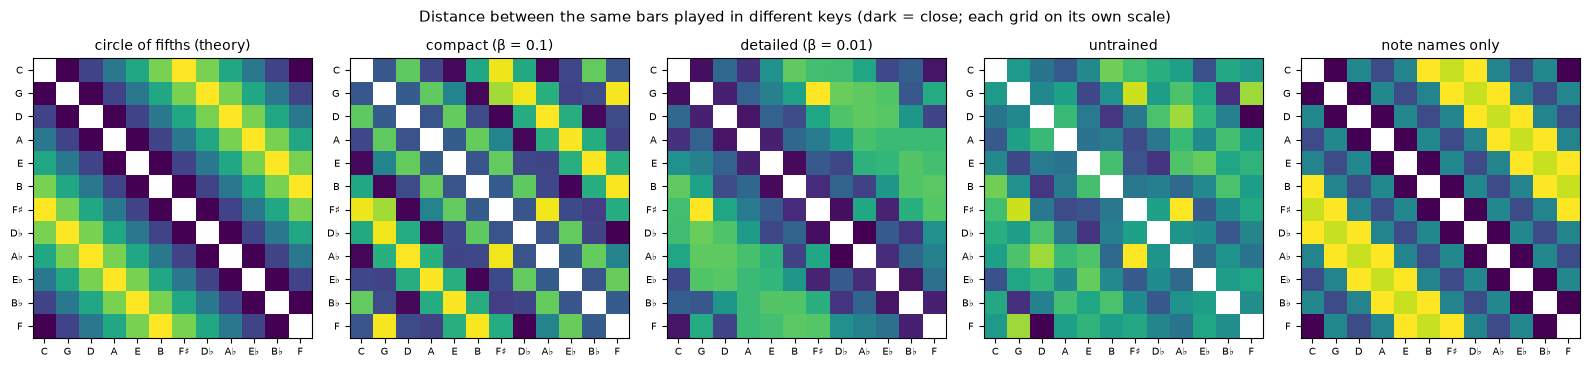

In [2]:
def distance_matrix(vectors):
    # vectors[s]: one row per bar for the version shifted by s semitones
    return np.array([[np.linalg.norm(vectors[a] - vectors[b], axis=1).mean() for b in shifts]
                     for a in shifts])

codes = {name: {s: encode_notes(model, versions[s])[0] for s in shifts}
         for name, model in models.items()}
distances = {name: distance_matrix(c) for name, c in codes.items()}
note_names = {s: bar_features(notes_table(versions[s]), pd.Series([16] * len(bars_in_c)))
              [[f"pc_{n}" for n in PITCH_CLASSES]].fillna(0).to_numpy() for s in shifts}
distances["note names only"] = distance_matrix(note_names)

order = [keys.index(k) for k in CIRCLE]
labels = [KEY_NAMES[k] for k in CIRCLE]
theory = np.array([[fifths_distance(a, b) for b in keys] for a in keys], float)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (name, d) in zip(axes, [("circle of fifths (theory)", theory)] + list(distances.items())):
    d = d[np.ix_(order, order)].copy()
    np.fill_diagonal(d, np.nan)  # a key's distance to itself (0) would squash the colour scale
    ax.imshow(d, cmap="viridis", vmin=np.nanmin(d), vmax=np.nanmax(d))
    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(12), labels, fontsize=7)
    ax.set_yticks(range(12), labels, fontsize=7)
fig.suptitle("Distance between the same bars played in different keys (dark = close; each grid on its own scale)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "key_distances.png", dpi=150)

We test four ideas about what shapes these distances, each a *hypothesis* about which keys
should be close:

- **circle of fifths**: neighbours on the circle are close (C next to G and F);
- **major-third groups**: keys a major third apart are close (C with E and A♭, which divide the
  octave into three equal steps);
- **minor-third groups**: keys a minor third apart are close (C with E♭, F♯ and A);
- **pitch**: keys are close when they are close in pitch (C next to C♯ and B).

For each, the score is a rank correlation between the measured distances and the hypothesis
(1 means the hypothesis orders the distances perfectly, 0 means it has nothing to do with them),
and the *p-value* is the chance of matching as well by luck, estimated by shuffling the keys
10,000 times (below 0.01: very unlikely to be luck).

In [3]:
hypotheses = {
    "circle of fifths": theory,
    "major-third groups": np.array([[0 if (a - b) % 4 == 0 else 1 for b in keys] for a in keys], float),
    "minor-third groups": np.array([[0 if (a - b) % 3 == 0 else 1 for b in keys] for a in keys], float),
    "pitch": np.abs(np.subtract.outer(shifts, shifts)).astype(float),
}
rows = []
for name, d in distances.items():
    for hypothesis, h in hypotheses.items():
        rho, p = mantel(d, h)
        rows.append({"codes": name, "hypothesis": hypothesis, "score": rho, "p-value": p})
results = pd.DataFrame(rows)
display(results.pivot(index="codes", columns="hypothesis", values="score").loc[list(distances)]
        .round(2))
display(results.pivot(index="codes", columns="hypothesis", values="p-value").loc[list(distances)]
        .map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"))

nearest = pd.DataFrame({name: [KEY_NAMES[keys[k]] for k in np.argsort(d[shifts.index(0)])[1:5]]
                        for name, d in distances.items()}, index=["1st", "2nd", "3rd", "4th"])
print("Closest keys to C:")
display(nearest)

hypothesis,circle of fifths,major-third groups,minor-third groups,pitch
codes,,,,
compact (β = 0.1),0.15,0.67,-0.06,-0.11
detailed (β = 0.01),0.89,-0.21,0.01,-0.12
untrained,0.36,0.04,0.45,-0.08
note names only,0.75,0.08,0.13,-0.49


hypothesis,circle of fifths,major-third groups,minor-third groups,pitch
codes,,,,
compact (β = 0.1),0.135,< 0.001,0.649,0.828
detailed (β = 0.01),< 0.001,0.960,0.437,0.856
untrained,0.003,0.384,< 0.001,0.740
note names only,< 0.001,0.288,0.180,1.000


Closest keys to C:


,compact (β = 0.1),detailed (β = 0.01),untrained,note names only
1st,A♭,G,E♭,G
2nd,E,F,A,F
3rd,E♭,A,D,A
4th,A,E♭,E,E♭


To check that this isn't a fluke of the particular bars, we repeat the measurement on two
separate halves of the 600 bars.

In [4]:
halves = {"first 300 bars": slice(0, 300), "last 300 bars": slice(300, 600)}
check = pd.DataFrame({
    (name, hypothesis): {half: mantel(distance_matrix({s: c[s][rows] for s in shifts}),
                                      hypotheses[hypothesis], n_permutations=1000)[0]
                         for half, rows in halves.items()}
    for name, c in codes.items() for hypothesis in ["circle of fifths", "major-third groups"]})
display(check.round(2))

compact (β = 0.1)                    detailed (β = 0.01)  \
                circle of fifths major-third groups    circle of fifths   
first 300 bars              0.16               0.67                0.89   
last 300 bars               0.15               0.65                0.89   

                                         untrained                     
               major-third groups circle of fifths major-third groups  
first 300 bars              -0.21             0.42               0.06  
last 300 bars               -0.21             0.25               0.02

## What the models found

**The detailed model has rediscovered the circle of fifths.** Its closest keys to C are G and F,
its neighbours on the circle, and the circle of fifths orders its distances almost perfectly
(score 0.89). It does so even better than the note-names reference (0.75), which knows exactly
which notes each version contains. Nothing in the model's training mentioned keys: it only had
to play bars back, and it ended up arranging the keys the way musicians do.

**The compact model organised keys differently: by major thirds.** For it, C is closest to A♭
and E, the keys that split the octave into three equal steps (score 0.67), and the circle of
fifths plays no clear role. This is also a structure music theorists know, though a less
familiar one, and it echoes what the original thesis found inside the model's chord
representations ("four groups of major thirds"). We don't have a simple explanation for why the
compact model prefers it. One possibility is that, with less room in its code, it keeps a
coarser summary of pitch that happens to repeat every four semitones.

**The untrained control shows some structure too** (minor-third groups, and a weak circle of
fifths), a reminder that an architecture alone can impose patterns. But neither trained model
shows that pattern: training replaced it.

**Pitch distance plays no role** for any model: a version one semitone higher is as different,
for the model, as one five semitones higher. That fits the second notebook, where the code
stored notes at their actual pitches rather than as a melody shape plus a key.

## Listen

The same bar in C, then in G (a neighbour on the circle of fifths: six of seven notes shared),
then in F♯ (the opposite side of the circle: two notes shared). The first change sounds like a
gentle shift, the second like a jump to a foreign world.

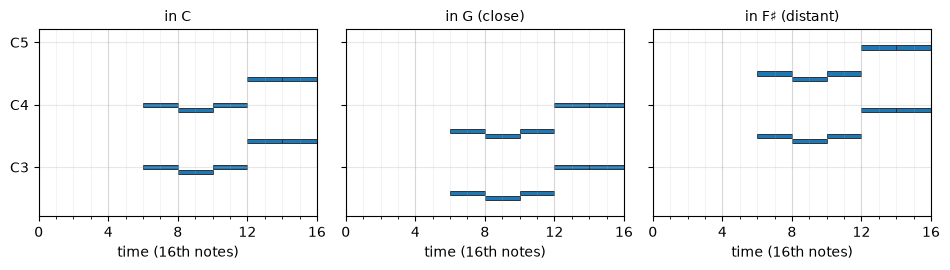

Listen: [one_bar_three_keys.mp3](outputs/q3/one_bar_three_keys.mp3)

In [5]:
example = next(notes for notes in bars_in_c if 8 <= len(notes) <= 14)
in_keys = [example, transpose(example, -5), transpose(example, 6)]  # C, G (below), F♯ (above)
titles = ["in C", "in G (close)", "in F♯ (distant)"]
fig = plot_bars(in_keys, titles, [16] * 3)
fig.savefig(OUT / "one_bar_three_keys.png", dpi=150)
plt.show()
save_mp3(synthesize(in_keys, [16] * 3, gap_steps=4), OUT / "one_bar_three_keys.mp3")
to_midi(in_keys, OUT / "one_bar_three_keys.mid", [16] * 3, gap_steps=4)
listen(OUT / "one_bar_three_keys.mp3")

## Summary

- **A piece of music theory emerged without being taught.** The detailed model places keys
  according to the circle of fifths, more faithfully than simply comparing which notes they use.
- **How much the model may remember changes what it learns.** The compact model, with less room
  in its code, organised keys in a different way (by major thirds), which also appeared in the
  original thesis.
- **The structure comes from training, not from the architecture:** the untrained control shows
  a different, weaker pattern.

This is as far as we go into music theory. The last notebook turns to the question that
motivated the whole project: what the latent space says about composers and the history of
music.